In [61]:
# load the library
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import plot_decision_regions
import warnings 
warnings.filterwarnings('ignore')

In [62]:
#load the datasets.
df = pd.read_csv("../placement_dataset.csv")
df.head()

,CGPA,ScoreBias,Placed
0,3.8,85,1
1,3.2,72,0
2,3.9,88,1
3,2.5,65,0
4,3.5,79,1


In [63]:
# check the null values.
df.isnull().sum()

CGPA         0
ScoreBias    0
Placed       0
dtype: int64

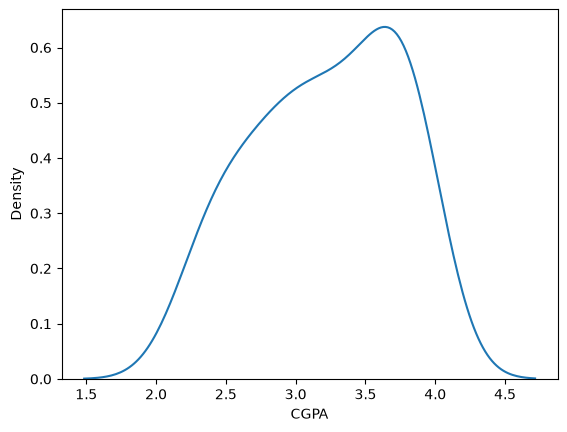

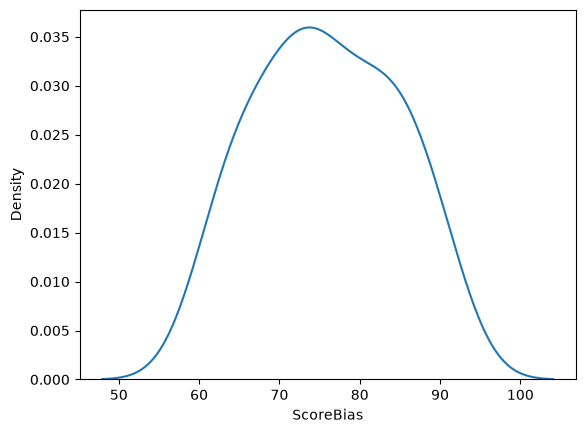

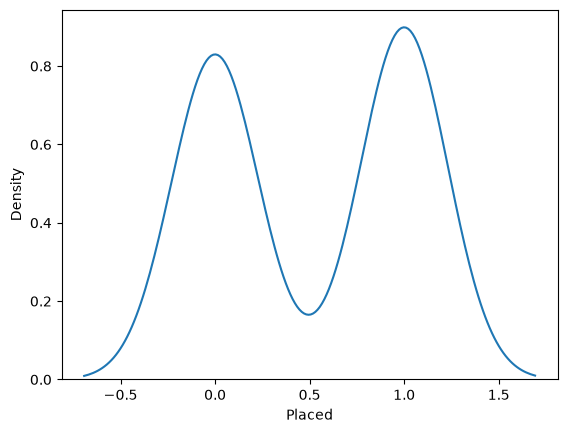

In [64]:
# check the data it follows normal distribution or not.
for i in df.columns:
    sns.kdeplot(df[i])
    plt.show()

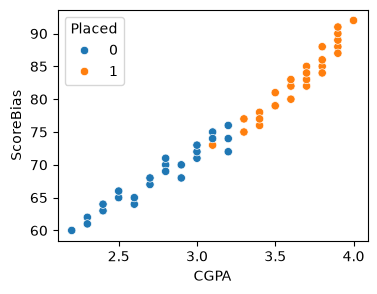

In [65]:
# check the linear seperable or non seperable data.
plt.figure(figsize=(4,3))
sns.scatterplot(x = 'CGPA' , y = 'ScoreBias' , data=df , hue='Placed')
plt.show()

In [66]:
# 1 data point is miss classification

In [67]:
df['Placed'].value_counts()

Placed
1    26
0    24
Name: count, dtype: int64

In [68]:
# Differentating the data into independent and Dependent variables.
x = df.iloc[:,:-1]
y = df['Placed']

In [69]:
# splitting the data into train and test split.
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)


In [70]:
from sklearn.naive_bayes import GaussianNB,BernoulliNB,MultinomialNB
gnb = GaussianNB()
gnb.fit(x_train,y_train)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[19.,21.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.47,0.53]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,7.718e-08
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['CGPA','ScoreBias']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 2)","[[ 2.75,68.37], [ 3.66,83.19]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 2)","[[ 0.08,17.81], [ 0.05,26.54]]"


In [71]:
gnb.score(x_test,y_test) * 100 , gnb.score(x_train,y_train) * 100

(100.0, 97.5)

In [72]:
mnb = MultinomialNB()
mnb.fit(x_train,y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[19.,21.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.74,-0.64]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 2)","[[ 52.3,1299. ], [ 76.9,1747. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 2)","[[-3.23,-0.04], [-3.15,-0.04]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['CGPA','ScoreBias']"


In [73]:
mnb.score(x_test,y_test) * 100 , mnb.score(x_train,y_train) * 100

(50.0, 52.5)

In [74]:
ber = BernoulliNB()
ber.fit(x_train,y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"binarize binarize: float or None, default=0.0Threshold for binarizing (mapping to booleans) of sample features.If None, input is presumed to already consist of binary vectors.",0.0
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[19.,21.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Log probability of each class (smoothed).","ndarray[float64](2,)","[-0.74,-0.64]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 2)","[[19.,19.], [21.,21.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of features given a class, P(x_i|y).","ndarray[float64](2, 2)","[[-0.05,-0.05], [-0.04,-0.04]]"


In [75]:
ber.score(x_test,y_test) * 100 , ber.score(x_train,y_train) * 100

(50.0, 52.5)

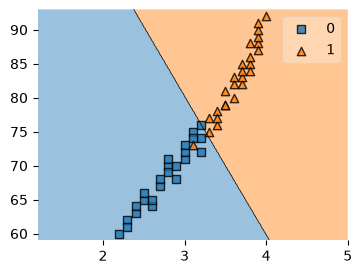

In [76]:
# plotting decesion regisions for Gaussian Navie Bayes
plt.figure(figsize=(4,3))
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x.to_numpy(),y.to_numpy(),clf = gnb)
plt.show()


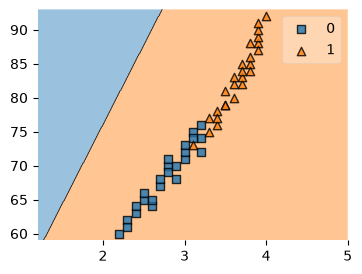

In [77]:
# plotting decision regision for Multinomial Navie Bayes.
plt.figure(figsize=(4,3))
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x.to_numpy(),y.to_numpy(), clf = mnb)
plt.show()

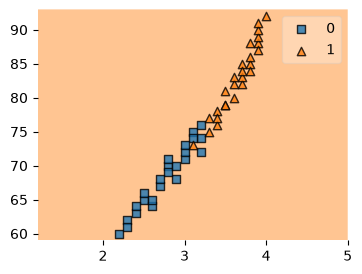

In [78]:
# plotting decision for Bernouli Navie Bayes
plt.figure(figsize=(4,3))
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x.to_numpy() , y.to_numpy() , clf = ber)
plt.show()

# conclusion
from our analyis we conclude that the score for Gaussian Navie Bayes is better as comaprision  of Multinomial and Bernouli Navie Bayes after the plotting decision region Navie Bayes is differentating the linear sepaerable data.
so we choose 

In [79]:
# let's predict the model.
gnb.predict([[3.8,85]])

array([1])

# Pandas profiling
pandas profiling is a python library that helps us to do the EDA in a single line of code.


In [ ]:
from ydata_profiling import ProfileReport